
<p align="center"> In the Name of God </p>

<table style="width: 100%; text-align: center;">
  <tr>
    <td style="width: 20%;"><img src="https://i.ibb.co/yXKQmtZ/logo1.png" alt="Left Logo" width="100"></td>
    <td style="width: 60%;">
      <p>Faculty of Electrical and Computer Engineering</p>
      <p>Interactive learning - Fall 2023-2024</p>
      <p>Assignment Series 2</p>
      <p>Markov Decision Processes and Dynamic programming</p>
    </td>
    <td style="width: 20%;"><img src="https://i.ibb.co/wLjqFkw/logo2.png" alt="Right Logo" width="100"></td>
  </tr>
  
</table>
<p align="center">Fatemeh Mohammadi - 810199489</p>
<hr>



In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from sympy import symbols, solveset, Interval, nsolve
import time
import timeit



# <font color = lightGreen> Problem 3: 
 </font>

# <font color = lightGreen> Problem 4: 
 </font>

## PART 1: (Questions)

### 4.1.D

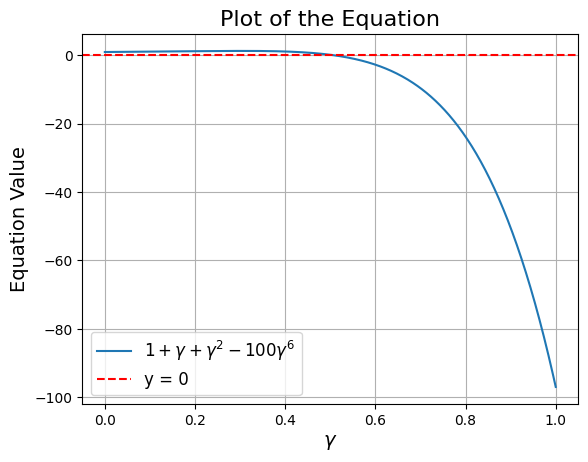

In [2]:
def equation(gamma_):
    return 1 + gamma_ + gamma_**2 - (100 * gamma_**6)

gamma_values = np.linspace(0, 1, 500)
equation_values = equation(gamma_values)

plt.plot(gamma_values, equation_values, label=r"$1 + \gamma + \gamma^2 - 100\gamma^6$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\gamma$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [3]:
gamma_sym = symbols('gamma', positive=True, real=True)
equation_1 = 1 + gamma_sym + gamma_sym**2 - 100 * gamma_sym**6

root1 = nsolve(equation_1, gamma_sym, 0.9)
root1

0.510558830219454

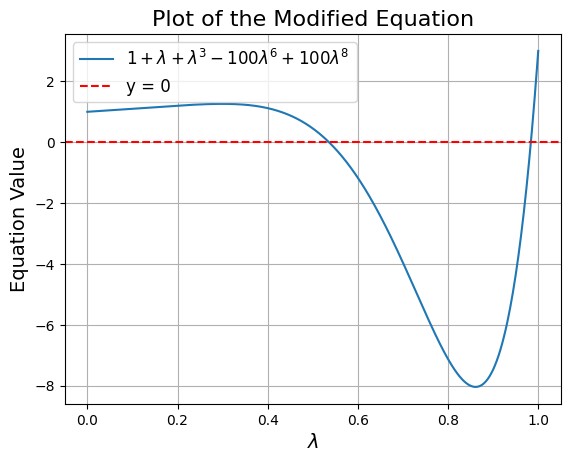

In [4]:
def modified_equation(gamma_):
    return 1 + gamma_ + gamma_**3 - (100 * gamma_**6) + (100 * gamma_**8)

gamma_values = np.linspace(0, 1, 500)
modified_equation_values = modified_equation(gamma_values)

plt.plot(gamma_values, modified_equation_values, label=r"$1 + \lambda + \lambda^3 - 100\lambda^6 + 100\lambda^8$")
plt.axhline(0, color='red', linestyle='--', label="y = 0")
plt.xlabel(r"$\lambda$", fontsize=14)
plt.ylabel("Equation Value", fontsize=14)
plt.title("Plot of the Modified Equation", fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()


In [5]:
lambda_sym = symbols('lambda', positive=True, real=True)
equation_2 = 1 + lambda_sym + lambda_sym**3 - 100 * lambda_sym**6 + 100 * lambda_sym**8

roots = solveset(equation_2, lambda_sym, domain=Interval(0, 1))

root1 = nsolve(equation_2, lambda_sym, 0.5)
root2 = nsolve(equation_2, lambda_sym, 0.9)
(root1, root2)

(0.535996345399022, 0.983664801927083)

## PART 2: (Simulation)

### Define MDP parameters:

In [6]:
## State Space S:
states = list(range(11))

## Action Space A:
actions = ["Buy", "Sell"]

## Transition Probabilities P:
def transitions(current_s, a): #P(current_s,a) -> {next_s: probability = 1}
    next_s = 0
    probability = 1 # Deterministic

    if a == "Buy":
        if current_s < 10:
            next_s = current_s + 1
        else:
            next_s = current_s
    elif a == "Sell":
        if current_s > 0:
            next_s = current_s - 1
        else:
            next_s = current_s

    return {next_s: probability}


## Reward Function R:
def rewards(current_s, a, next_s):
    reward = 0
    if a == "Buy":
        if current_s == 9 and next_s == 10:
            reward = 100
        else:
            reward = 0
    elif a == "Sell":
        if current_s > 0 and next_s == current_s - 1:
            reward = 1
        else:
            reward = 0
    return reward


### 4.2.A.

#### Policy Iteration:

In [66]:
def finite_horizon_policy_iteration(states, actions, H, transitions, rewards, gamma = 1):
    #0. Initialize random policy
    policy = { (s, t): (np.random.choice(actions) if s != 10 else None) for s in states for t in range(H) }

    while True:
        #1. Initialize value function
        V = { (s, t): 0 for s in states for t in range(H+1) }

        #2. Policy Evaluation
        for t in range(H - 1, -1, -1):  # Iterate backward from H->0
            for s in states:
                if s == 10:  # Terminal state
                    continue
                a = policy[(s, t)]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])
                V[(s, t)] = value


        #3. Policy Improvement
        stable = True
        for t in range(H):
            for s in states:
                if s == 10:  # Terminal state
                    continue

                best_action = None
                best_value = float('-inf')

                for a in actions:
                    value = 0
                    for next_s, prob in transitions(s, a).items():
                        value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])
                    if value > best_value:
                        best_value = value
                        best_action = a

                if policy[(s, t)] != best_action:
                    stable = False
                    policy[(s, t)] = best_action

        if stable:
            break  # Policy has converged

    return policy , V

In [67]:
# For Debug:
H = 7
policy, V = finite_horizon_policy_iteration(states, actions, H, transitions, rewards)
V

{(0, 0): 3,
 (0, 1): 3,
 (0, 2): 2,
 (0, 3): 2,
 (0, 4): 1,
 (0, 5): 1,
 (0, 6): 0,
 (0, 7): 0,
 (1, 0): 4,
 (1, 1): 3,
 (1, 2): 3,
 (1, 3): 2,
 (1, 4): 2,
 (1, 5): 1,
 (1, 6): 1,
 (1, 7): 0,
 (2, 0): 4,
 (2, 1): 4,
 (2, 2): 3,
 (2, 3): 3,
 (2, 4): 2,
 (2, 5): 2,
 (2, 6): 1,
 (2, 7): 0,
 (3, 0): 100,
 (3, 1): 4,
 (3, 2): 4,
 (3, 3): 3,
 (3, 4): 3,
 (3, 5): 2,
 (3, 6): 1,
 (3, 7): 0,
 (4, 0): 100,
 (4, 1): 100,
 (4, 2): 4,
 (4, 3): 4,
 (4, 4): 3,
 (4, 5): 2,
 (4, 6): 1,
 (4, 7): 0,
 (5, 0): 101,
 (5, 1): 100,
 (5, 2): 100,
 (5, 3): 4,
 (5, 4): 3,
 (5, 5): 2,
 (5, 6): 1,
 (5, 7): 0,
 (6, 0): 101,
 (6, 1): 101,
 (6, 2): 100,
 (6, 3): 100,
 (6, 4): 3,
 (6, 5): 2,
 (6, 6): 1,
 (6, 7): 0,
 (7, 0): 102,
 (7, 1): 101,
 (7, 2): 101,
 (7, 3): 100,
 (7, 4): 100,
 (7, 5): 2,
 (7, 6): 1,
 (7, 7): 0,
 (8, 0): 102,
 (8, 1): 102,
 (8, 2): 101,
 (8, 3): 101,
 (8, 4): 100,
 (8, 5): 100,
 (8, 6): 1,
 (8, 7): 0,
 (9, 0): 103,
 (9, 1): 102,
 (9, 2): 102,
 (9, 3): 101,
 (9, 4): 101,
 (9, 5): 100,
 (9, 6): 1

#### Value Iteration:

In [68]:
def finite_horizon_value_iteration(states, actions, H, transitions, rewards, gamma = 1):
    # 1. Initialize value function for all states and time steps
    V = { (s, t): 0 for s in states for t in range(H+1) }
    policy = { (s, t): None for s in states for t in range(H) }

    # 2. Perform value iteration backward from horizon H
    for t in range(H - 1, -1, -1):  # Iterate backward from H-1 to 0
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            #2.1. Evaluate each action
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[(next_s, t+1)])

                if value > best_value:
                    best_value = value
                    best_action = a

            #2.2. Update the value function and policy
            V[(s, t)] = best_value
            policy[(s, t)] = best_action

    return policy, V


In [69]:
# For Debug:
H = 7
policy, V = finite_horizon_value_iteration(states, actions, H, transitions, rewards)
V


{(0, 0): 3,
 (0, 1): 3,
 (0, 2): 2,
 (0, 3): 2,
 (0, 4): 1,
 (0, 5): 1,
 (0, 6): 0,
 (0, 7): 0,
 (1, 0): 4,
 (1, 1): 3,
 (1, 2): 3,
 (1, 3): 2,
 (1, 4): 2,
 (1, 5): 1,
 (1, 6): 1,
 (1, 7): 0,
 (2, 0): 4,
 (2, 1): 4,
 (2, 2): 3,
 (2, 3): 3,
 (2, 4): 2,
 (2, 5): 2,
 (2, 6): 1,
 (2, 7): 0,
 (3, 0): 100,
 (3, 1): 4,
 (3, 2): 4,
 (3, 3): 3,
 (3, 4): 3,
 (3, 5): 2,
 (3, 6): 1,
 (3, 7): 0,
 (4, 0): 100,
 (4, 1): 100,
 (4, 2): 4,
 (4, 3): 4,
 (4, 4): 3,
 (4, 5): 2,
 (4, 6): 1,
 (4, 7): 0,
 (5, 0): 101,
 (5, 1): 100,
 (5, 2): 100,
 (5, 3): 4,
 (5, 4): 3,
 (5, 5): 2,
 (5, 6): 1,
 (5, 7): 0,
 (6, 0): 101,
 (6, 1): 101,
 (6, 2): 100,
 (6, 3): 100,
 (6, 4): 3,
 (6, 5): 2,
 (6, 6): 1,
 (6, 7): 0,
 (7, 0): 102,
 (7, 1): 101,
 (7, 2): 101,
 (7, 3): 100,
 (7, 4): 100,
 (7, 5): 2,
 (7, 6): 1,
 (7, 7): 0,
 (8, 0): 102,
 (8, 1): 102,
 (8, 2): 101,
 (8, 3): 101,
 (8, 4): 100,
 (8, 5): 100,
 (8, 6): 1,
 (8, 7): 0,
 (9, 0): 103,
 (9, 1): 102,
 (9, 2): 102,
 (9, 3): 101,
 (9, 4): 101,
 (9, 5): 100,
 (9, 6): 1

#### Simulation

In [75]:
def simulate_actions_for_horizon(H, start_state, states, actions, transitions, rewards, algorithm, gamma = 1):
    # Compute the optimal policy for the horizon

    policy, _ = algorithm(states, actions, H, transitions, rewards, gamma)

    # Simulate the trajectory
    current_state = start_state
    trajectory = []
    for t in range(H):
        if current_state == 10:  # Terminal state
            trajectory.append((t, current_state, None))
            break

        # Get the action from policy
        action = policy.get((current_state, t), None)
        trajectory.append((t, current_state, action))

        # Updating state
        next_states = transitions(current_state, action)
        current_state = list(next_states.keys())[0]  # Deterministic transition

    return trajectory


def simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, algorithm, gamma = 1):
    for H in Hs:
        # Simulate the trajectory for the given H
        trajectory = simulate_actions_for_horizon(H, start_state, states, actions, transitions, rewards, algorithm, gamma)

        buy_count = sum(1 for _, _, a in trajectory if a == "Buy")
        sell_count = sum(1 for _, _, a in trajectory if a == "Sell")

        # Categorize the policy
        if sell_count == 0:
            policy_type = "Buy-only policy"
        elif buy_count == 0:
            policy_type = "Sell-only policy"
        else:
            policy_type = "Mixed policy (buy and sell)"

        # Results
        print(f"H = {H},\t#Sell = {sell_count},\t#Buy = {buy_count},\t-> {policy_type}")
        for t, s, a in trajectory:
            print(f"Time Step: {t}, State: {s}, Action: {a}")
        print(10 * "___")


In [76]:
Hs = [3, 5, 7, 8, 9, 12]
start_state = 3


In [77]:
print("PI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)


PI:
H = 3,	#Sell = 3,	#Buy = 0,	-> Sell-only policy
Time Step: 0, State: 3, Action: Sell
Time Step: 1, State: 2, Action: Sell
Time Step: 2, State: 1, Action: Sell
______________________________
H = 5,	#Sell = 4,	#Buy = 1,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Sell
Time Step: 2, State: 3, Action: Sell
Time Step: 3, State: 2, Action: Sell
Time Step: 4, State: 1, Action: Sell
______________________________
H = 7,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Buy
______________________________
H = 8,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 

In [78]:
print("VI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)



VI:
H = 3,	#Sell = 3,	#Buy = 0,	-> Sell-only policy
Time Step: 0, State: 3, Action: Sell
Time Step: 1, State: 2, Action: Sell
Time Step: 2, State: 1, Action: Sell
______________________________
H = 5,	#Sell = 4,	#Buy = 1,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Sell
Time Step: 2, State: 3, Action: Sell
Time Step: 3, State: 2, Action: Sell
Time Step: 4, State: 1, Action: Sell
______________________________
H = 7,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Buy
______________________________
H = 8,	#Sell = 0,	#Buy = 7,	-> Buy-only policy
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 

#### Compare PI & VI:

In [74]:
Hs = [np.random.randint(20)]
start = np.random.randint(10)
print("PI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)
print("VI:")
simulate_and_categorize(Hs, start_state, states, actions, transitions, rewards, finite_horizon_value_iteration)


PI:
H = 12,	#Sell = 2,	#Buy = 9,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Sell
Time Step: 7, State: 8, Action: Buy
Time Step: 8, State: 9, Action: Sell
Time Step: 9, State: 8, Action: Buy
Time Step: 10, State: 9, Action: Buy
Time Step: 11, State: 10, Action: No Action
______________________________
VI:
H = 12,	#Sell = 2,	#Buy = 9,	-> Mixed policy (buy and sell)
Time Step: 0, State: 3, Action: Buy
Time Step: 1, State: 4, Action: Buy
Time Step: 2, State: 5, Action: Buy
Time Step: 3, State: 6, Action: Buy
Time Step: 4, State: 7, Action: Buy
Time Step: 5, State: 8, Action: Buy
Time Step: 6, State: 9, Action: Sell
Time Step: 7, State: 8, Action: Buy
Time Step: 8, State: 9, Action: Sell
Time Step: 9, State: 8, Action: Buy
Time Step: 10, State: 9, Action: Buy

In [87]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: finite_horizon_policy_iteration(states, actions, H, transitions, rewards), number=1)
    execution_time_VI = timeit.timeit(lambda: finite_horizon_value_iteration(states, actions, H, transitions, rewards), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.06501 seconds
Avg Execution Time - VI: 0.00547 seconds


### 4.2.B. 

In [88]:
gamma = 0


#### Policy Iteration

In [89]:
def infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=0, epsilon=0.00001):
    # 0. Initialize random policy
    policy = {s: (np.random.choice(actions) if s != 10 else None) for s in states}

    while True:
        #1. Initialize value function
        V = {s: 0 for s in states}

        #2. Policy Evaluation
        while True:
            delta = 0
            for s in states:
                if s == 10:  # Terminal state
                    continue
                a = policy[s]
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])
                delta = max(delta, abs(V[s] - value))
                V[s] = value
            if delta < epsilon:  # Value function has converged
                break

        #2. Policy Improvement
        stable = True
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])
                if value > best_value:
                    best_value = value
                    best_action = a

            if policy[s] != best_action:
                stable = False
                policy[s] = best_action

        if stable:
            break  # Policy has converged

    return policy, V


In [90]:
policy, V= infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
policy

{0: 'Buy',
 1: 'Sell',
 2: 'Sell',
 3: 'Sell',
 4: 'Sell',
 5: 'Sell',
 6: 'Sell',
 7: 'Sell',
 8: 'Sell',
 9: 'Buy',
 10: None}

#### Value Iteration

In [91]:
def infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=0, epsilon=0.00001):
    # 1. Initialize value function and policy for all states
    V = {s: 0 for s in states}
    policy = {s: None for s in states}

    while True:
        delta = 0
        # 2. Perform value iteration across all states
        for s in states:
            if s == 10:  # Terminal state
                continue

            best_action = None
            best_value = float('-inf')

            # 2.1 Evaluate each action
            for a in actions:
                value = 0
                for next_s, prob in transitions(s, a).items():
                    value += prob * (rewards(s, a, next_s) + gamma * V[next_s])

                if value > best_value:
                    best_value = value
                    best_action = a

            # 2.2 Update the value function and policy
            delta = max(delta, abs(V[s] - best_value))
            V[s] = best_value
            policy[s] = best_action

        # 3. Check for convergence
        if delta < epsilon:  # Value function has converged
            break

    return policy, V


In [92]:
policy, V= infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
policy

{0: 'Buy',
 1: 'Sell',
 2: 'Sell',
 3: 'Sell',
 4: 'Sell',
 5: 'Sell',
 6: 'Sell',
 7: 'Sell',
 8: 'Sell',
 9: 'Buy',
 10: None}

#### Compare PI & VI:

In [83]:
print("PI:")
policy_PI, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
print(policy_PI)
print("VI:")
policy_VI, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
print(policy_VI)


PI:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}
VI:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}


In [86]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001), number=1)
    execution_time_VI = timeit.timeit(lambda: infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00010 seconds
Avg Execution Time - VI: 0.00002 seconds


### 4.2.C. 

In [120]:
gammas = [0.0, 0.1, 0.5, 0.9]


#### Policy Iteration

In [125]:
gammas = [0.0, 0.1, 0.5, 0.9]
for gamma in gammas:
    print(f"gamma = {gamma}:")
    policy, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
    print(policy)
    print("")


gamma = 0.0:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}

gamma = 0.1:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.9:
{0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}



#### Value Iteration

In [ ]:
gammas = [0.0, 0.1, 0.5, 0.9]
for gamma in gammas:
    print(f"gamma = {gamma}:")
    policy, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
    print(policy)
    print("")

gamma = 0.0:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Sell', 9: 'Buy', 10: None}

gamma = 0.1:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5:
{0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.9:
{0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}



#### Compare PI & VI:

In [ ]:
for i in range(5):
    gamma = np.random.uniform()
    print(f"gamma = {gamma}:")
    policy_VI, _ = infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
    policy_PI, _ = infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001)
    if policy_PI == policy_VI:
        print("SAME")
        print("Policy:", policy_PI)
    else:
        print(f"policy_PI = {policy_PI}" )
        print(f"policy_VI = {policy_VI}" )

    print("")

gamma = 0.04954302777000463:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Sell', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.9013655726564299:
SAME
Policy: {0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.5537671909736548:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.6931246041044088:
SAME
Policy: {0: 'Buy', 1: 'Buy', 2: 'Buy', 3: 'Buy', 4: 'Buy', 5: 'Buy', 6: 'Buy', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}

gamma = 0.23430349836331754:
SAME
Policy: {0: 'Buy', 1: 'Sell', 2: 'Sell', 3: 'Sell', 4: 'Sell', 5: 'Sell', 6: 'Sell', 7: 'Buy', 8: 'Buy', 9: 'Buy', 10: None}



In [132]:
execution_times_PI = []
execution_times_VI = []

for i in range(10):
    gamma = np.random.uniform()
    H = np.random.randint(100, 1000)
    execution_time_PI = timeit.timeit(lambda: infinite_horizon_policy_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001), number=1)
    execution_time_VI = timeit.timeit(lambda: infinite_horizon_value_iteration(states, actions, transitions, rewards, gamma=gamma, epsilon=0.00001), number=1)
    execution_times_PI.append(execution_time_PI)
    execution_times_VI.append(execution_time_VI)

avg_execution_time_PI = sum(execution_times_PI) / len(execution_times_PI)
avg_execution_time_VI = sum(execution_times_VI) / len(execution_times_VI)

print(f"Avg Execution Time - PI: {avg_execution_time_PI:.5f} seconds")
print(f"Avg Execution Time - VI: {avg_execution_time_VI:.5f} seconds")


Avg Execution Time - PI: 0.00140 seconds
Avg Execution Time - VI: 0.00011 seconds
